# Modelo de Red FeedForward Base

Modelo base (baseline) de red para clasificar EuroSAT RGB (10 clases, 64x64x3). Es solo referencia para comparar contra la CNN del siguiente avance.

## 1. Configuración

In [ ]:
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from sklearn.model_selection import train_test_split

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIR_DATOS = RAIZ / "data" / "EuroSAT"
DIR_RESULTADOS = RAIZ / "resultados"
DIR_FIGURAS = DIR_RESULTADOS / "figures"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

TAM_LOTE = 64
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", dispositivo, "| torch", torch.__version__)

Dispositivo: cpu | torch 2.12.0+cpu


## 2. Datos

In [ ]:
# Carpetas en orden alfabético
clases = sorted(d.name for d in DIR_DATOS.iterdir() if d.is_dir())
rutas, etiquetas = [], []
for idx, clase in enumerate(clases):
    for ruta in sorted((DIR_DATOS / clase).glob("*.jpg")):
        rutas.append(ruta)
        etiquetas.append(idx)

X = np.stack([np.array(Image.open(r).convert("RGB"), dtype=np.uint8) for r in rutas])
y = np.array(etiquetas, dtype=np.int64)

assert len(clases) == 10
assert len(X) == 27000
assert X.shape[1:] == (64, 64, 3)
print(clases)
print("X:", X.shape, X.dtype, "| y:", y.shape)

['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
X: (27000, 64, 64, 3) uint8 | y: (27000,)


In [ ]:
# Partición 70/15/15. El test solo no se evalúa en este avance
X_ent, X_resto, y_ent, y_resto = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
X_val, X_prueba, y_val, y_prueba = train_test_split(
    X_resto, y_resto, test_size=0.50, stratify=y_resto, random_state=SEMILLA)
print("Entrenamiento:", len(X_ent), "| Validación:", len(X_val), "| Prueba (apartada):", len(X_prueba))

def a_tensor(imagenes):
    return torch.from_numpy(imagenes.astype(np.float32) / 255.0)

Xt_ent, Xt_val = a_tensor(X_ent).to(dispositivo), a_tensor(X_val).to(dispositivo)
yt_ent, yt_val = torch.from_numpy(y_ent).to(dispositivo), torch.from_numpy(y_val).to(dispositivo)

Entrenamiento: 18900 | Validación: 4050 | Prueba (apartada): 4050


## 3. Modelo

In [ ]:
def crear_modelo(capas=(256, 128)):
    # Flatten -> (Dense + ReLU + Dropout 0.5) por capa oculta -> Dense 10 (el softmax va en la pérdida)
    bloques, entrada = [nn.Flatten()], 64 * 64 * 3
    for unidades in capas:
        lineal = nn.Linear(entrada, unidades)
        nn.init.kaiming_normal_(lineal.weight, nonlinearity="relu")  
        nn.init.zeros_(lineal.bias)
        bloques += [lineal, nn.ReLU(), nn.Dropout(0.5)]
        entrada = unidades
    bloques.append(nn.Linear(entrada, 10))
    return nn.Sequential(*bloques)

def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())

assert contar_parametros(crear_modelo((256, 128))) == 3_180_170
print(crear_modelo((256, 128)))
print("Parámetros:", f"{contar_parametros(crear_modelo((256, 128))):,}")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=12288, out_features=256, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=256, out_features=128, bias=True)
  (5): ReLU()
  (6): Dropout(p=0.5, inplace=False)
  (7): Linear(in_features=128, out_features=10, bias=True)
)
Parámetros: 3,180,170


## 4. Entrenamiento del modelo base y curvas

In [ ]:
def entrenar(capas, lr, epocas, semilla=SEMILLA):
    """Entrena con época fija (sin early stopping) y devuelve el modelo y su historial por época."""
    torch.manual_seed(semilla)
    modelo = crear_modelo(capas).to(dispositivo)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    perdida_fn = nn.CrossEntropyLoss()  
    generador = torch.Generator().manual_seed(semilla)
    historial = {"perdida_ent": [], "exactitud_ent": [], "perdida_val": [], "exactitud_val": []}

    for _ in range(epocas):
        modelo.train()
        orden = torch.randperm(len(Xt_ent), generator=generador).to(dispositivo)
        suma_perdida, aciertos = 0.0, 0
        for i in range(0, len(orden), TAM_LOTE):
            idx = orden[i:i + TAM_LOTE]
            salida = modelo(Xt_ent[idx])
            perdida = perdida_fn(salida, yt_ent[idx])
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()
            suma_perdida += perdida.item() * len(idx)
            aciertos += (salida.argmax(1) == yt_ent[idx]).sum().item()
        
        historial["perdida_ent"].append(suma_perdida / len(Xt_ent))
        historial["exactitud_ent"].append(aciertos / len(Xt_ent))

        modelo.eval()
        with torch.no_grad():
            salida_val = modelo(Xt_val)
            historial["perdida_val"].append(perdida_fn(salida_val, yt_val).item())
            historial["exactitud_val"].append((salida_val.argmax(1) == yt_val).float().mean().item())
    return modelo, historial

def graficar_curvas(historial, titulo, archivo):
    fig, (ax_p, ax_e) = plt.subplots(1, 2, figsize=(11, 4))
    ep = range(1, len(historial["perdida_ent"]) + 1)
    ax_p.plot(ep, historial["perdida_ent"], label="Entrenamiento")
    ax_p.plot(ep, historial["perdida_val"], label="Validación")
    ax_p.set(title="Pérdida", xlabel="Época", ylabel="Entropía cruzada"); ax_p.legend()
    ax_e.plot(ep, historial["exactitud_ent"], label="Entrenamiento")
    ax_e.plot(ep, historial["exactitud_val"], label="Validación")
    ax_e.set(title="Exactitud", xlabel="Época", ylabel="Exactitud"); ax_e.legend()
    fig.suptitle(titulo)
    fig.tight_layout()
    fig.savefig(DIR_FIGURAS / archivo, dpi=120)
    plt.show()

Modelo base entrenado en 127.4 s
Última época -> val exactitud: 0.2696 | val pérdida: 1.9339


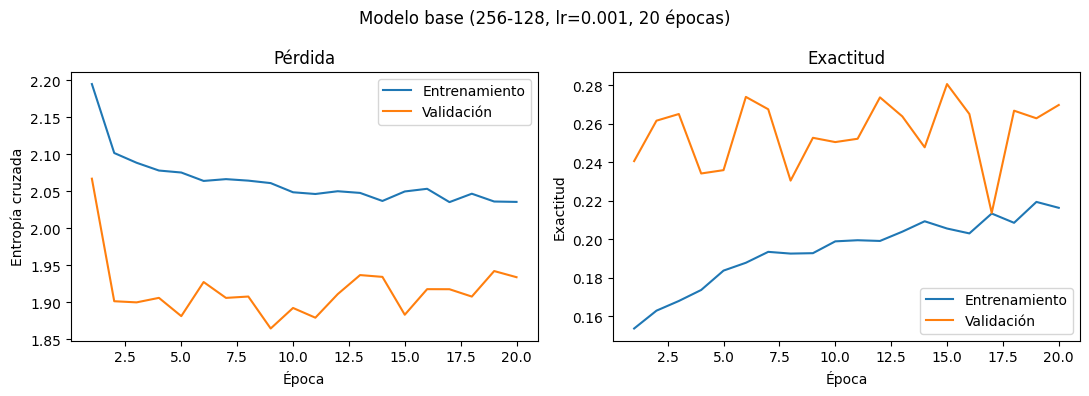

In [6]:
t0 = time.time()
modelo_base, hist_base = entrenar(capas=(256, 128), lr=1e-3, epocas=20)
print(f"Modelo base entrenado en {time.time() - t0:.1f} s")
print(f"Última época -> val exactitud: {hist_base['exactitud_val'][-1]:.4f} | val pérdida: {hist_base['perdida_val'][-1]:.4f}")
graficar_curvas(hist_base, "Modelo base (256-128, lr=0.001, 20 épocas)", "curvas_base.png")

## 5. Experimentos de hiperparámetros

Cada variante cambia una sola cosa respecto a R1 (base).

In [7]:
CONFIGURACIONES = {
    "R1": {"cambio": "base",          "capas": (256, 128), "lr": 1e-3, "epocas": 20},
    "R2": {"cambio": "lr = 0.0001",   "capas": (256, 128), "lr": 1e-4, "epocas": 20},
    "R3": {"cambio": "capas 512-256", "capas": (512, 256), "lr": 1e-3, "epocas": 20},
    "R4": {"cambio": "50 épocas",     "capas": (256, 128), "lr": 1e-3, "epocas": 50},
}

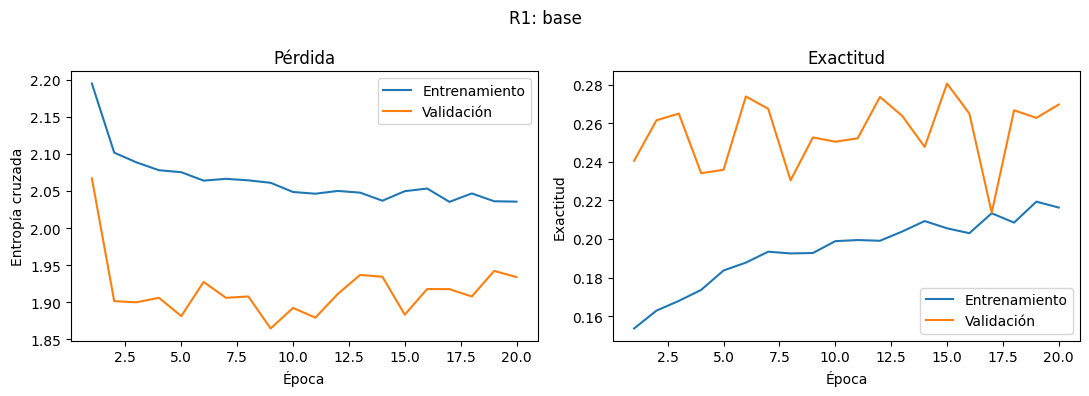

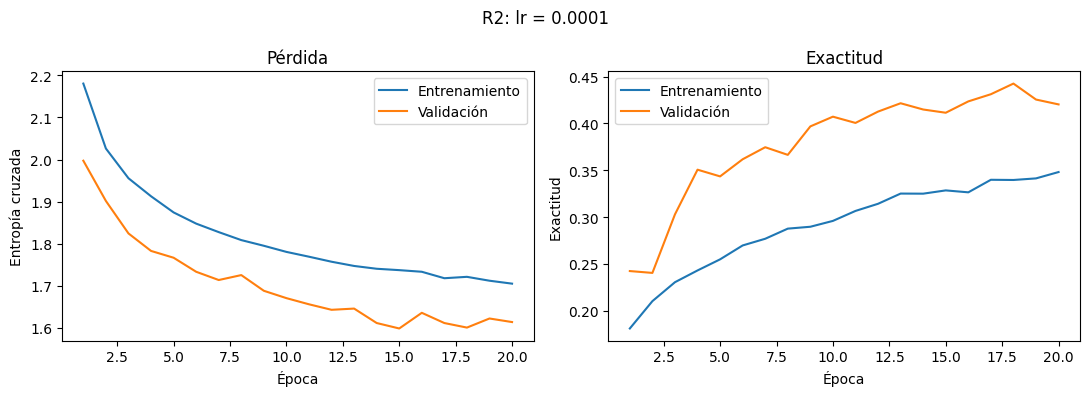

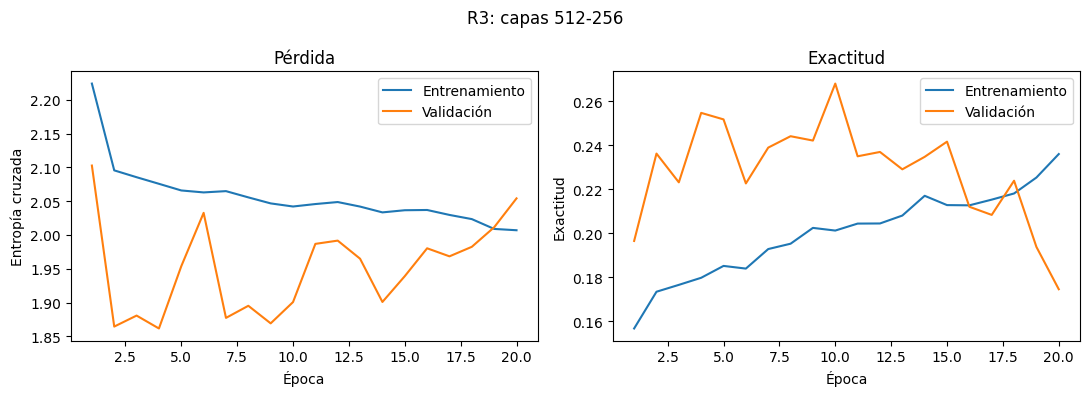

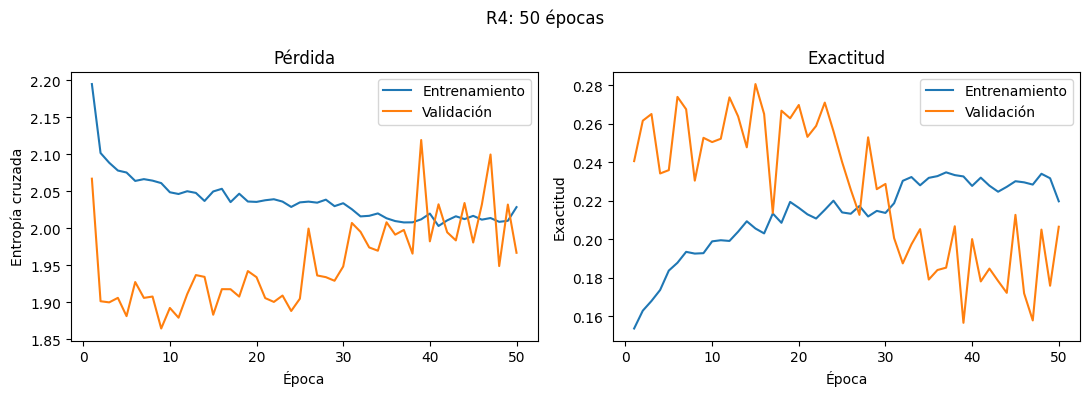

4 corridas en 1002.1 s


In [8]:
historiales, filas = {}, []
t0 = time.time()
for id_corrida, cfg in CONFIGURACIONES.items():
    modelo, h = entrenar(cfg["capas"], cfg["lr"], cfg["epocas"])
    historiales[id_corrida] = h
    graficar_curvas(h, f"{id_corrida}: {cfg['cambio']}", f"curvas_{id_corrida}.png")
    mejor = int(np.argmax(h["exactitud_val"]))
    filas.append({
        "id": id_corrida,
        "cambio": cfg["cambio"],
        "parametros": contar_parametros(modelo),
        "exactitud_ent": h["exactitud_ent"][-1],
        "perdida_ent": h["perdida_ent"][-1],
        "exactitud_val": h["exactitud_val"][-1],
        "perdida_val": h["perdida_val"][-1],
        "mejor_exactitud_val": h["exactitud_val"][mejor],
        "epoca_mejor": mejor + 1,
    })
print(f"4 corridas en {time.time() - t0:.1f} s")

In [9]:
resumen = pd.DataFrame(filas)
resumen.to_csv(DIR_RESULTADOS / "resumen_redFFbase.csv", index=False)
resumen.round(4)

,id,cambio,parametros,exactitud_ent,perdida_ent,exactitud_val,perdida_val,mejor_exactitud_val,epoca_mejor
0,R1,base,3180170,0.2162,2.0355,0.2696,1.9339,0.2805,15
1,R2,lr = 0.0001,3180170,0.3481,1.7048,0.4202,1.6135,0.4425,18
2,R3,capas 512-256,6425866,0.2361,2.0070,0.1746,2.0542,0.2681,10
3,R4,50 épocas,3180170,0.2196,2.0285,0.2064,1.9668,0.2805,15


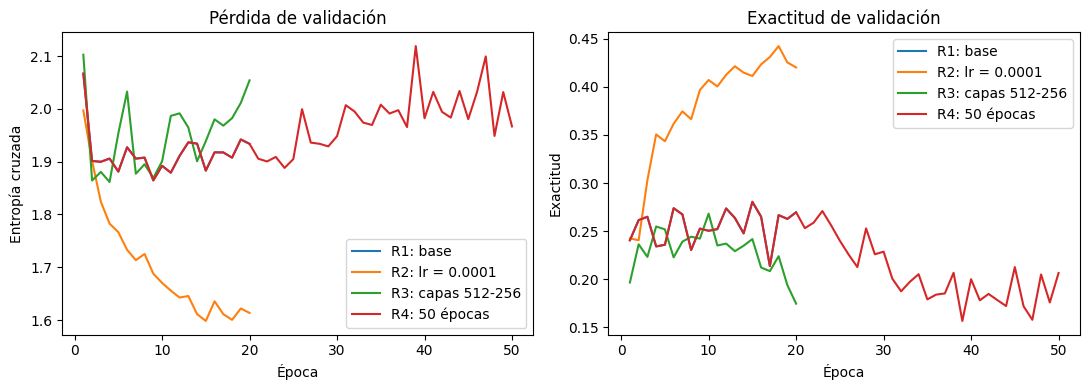

In [ ]:
# Comparación de curvas de validación de las 4 
fig, (ax_p, ax_e) = plt.subplots(1, 2, figsize=(11, 4))
for id_corrida, h in historiales.items():
    etiqueta = f"{id_corrida}: {CONFIGURACIONES[id_corrida]['cambio']}"
    ep = range(1, len(h["perdida_val"]) + 1)
    ax_p.plot(ep, h["perdida_val"], label=etiqueta)
    ax_e.plot(ep, h["exactitud_val"], label=etiqueta)
ax_p.set(title="Pérdida de validación", xlabel="Época", ylabel="Entropía cruzada"); ax_p.legend()
ax_e.set(title="Exactitud de validación", xlabel="Época", ylabel="Exactitud"); ax_e.legend()
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "comparacion_validacion.png", dpi=120)
plt.show()

## 6. Observaciones

- El modelo base (R1) aprende muy poco: llega a ~27% de exactitud de validación al final (máximo 28.0% en la época 15), apenas por encima del azar (10%). Las curvas de validación son ruidosas, lo que sugiere que con lr = 0.001 el entrenamiento es inestable para esta red.
- R2 (lr = 0.0001) fue la mejor corrida: 42.0% de validación al final y 44.2% como máximo (época 18), con curvas más suaves y todavía mejorando. Bajar la tasa de aprendizaje fue el cambio con mayor efecto.
- R3 (capas 512-256, 6,425,866 parámetros) no mejoró: terminó en 17.5% de validación (máximo 26.8%). Más capacidad no ayudó con lr = 0.001.
- R4 (50 épocas) repite R1 hasta la época 20 (misma semilla) y su máximo es el mismo (28.0%, época 15); entrenar más no mejoró y terminó en 20.6%.
- En todas las corridas la exactitud de entrenamiento es baja y cercana a la de validación (en R1 y R2 incluso menor), porque se calcula con Dropout 0.5 activo y promediada durante la época. No hay señal de sobreajuste; el problema es de subajuste/optimización.
- Estos resultados son bajos y sirven solo como referencia para comparar contra la CNN. Solo se usó una semilla, así que las diferencias entre corridas son indicativas.